<a href="https://colab.research.google.com/github/khanni1/Machine_learning/blob/clg/knn_assignment/my_knn_sklearn_knn_error_vs_k.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    n_classes=5,
    random_state=None
)

data = pd.DataFrame(X, columns=[f"feature_{i}" for i in range(10)])
data["tar"] = y

print(data)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def distance(a:list,b:list,n,p=2):
    # n dimensionals points an
    summ = 0
    for i in range(0,n):
        summ = summ + abs(a[i] - b[i])**p

    return summ**(1/p)

def knn(df,qp,tar,k=3,otype = 0,p=2):
    m = df.shape[0]
    n = df.shape[1]

    d = []


    for i in range(0,m):
        d.append(distance(list(df.iloc[i]),qp,n,p))

    res = pd.DataFrame({'distances' : d,'Y' : tar})

    res = res.sort_values(by = 'distances')

    res = res.head(k) #first k of sorted records

    if(otype == 0):
        return res
    elif(otype == 1):
        return res['Y'].mode()[0]



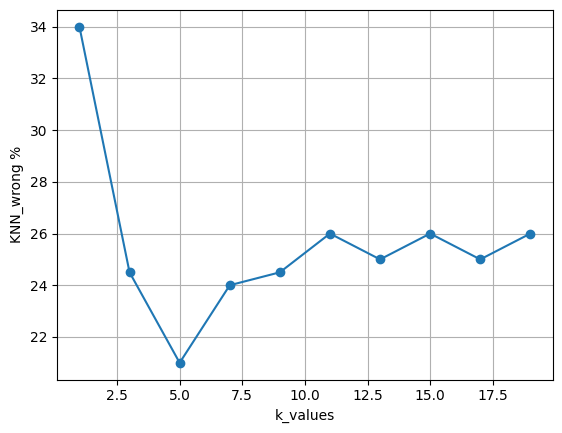

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


data_len = len(data)

trains = int(0.8*data_len)
tests = int(0.2*data_len)

training = data.head(trains)
testing = data.tail(tests)


wrong = []
k_value = []

x_testing = testing.drop(columns='tar')
x_training = training.drop(columns='tar')

for k in range(1,20,2):
    wrongs = 0
    for t in range(0,tests):
        prediction = knn(x_training , list(x_testing.iloc[t]) ,training['tar'],k,1)
        if prediction != testing.iloc[t]['tar']:
            wrongs += 1

    k_value.append(k)
    wrong.append(round(wrongs/tests,3)*100)

plt.plot(k_value,wrong,marker='o')
plt.grid(True)
plt.xlabel("k_values")
plt.ylabel("KNN_wrong %")
plt.show()









In [ ]:
from sklearn.neighbors import KNeighborsClassifier

wrong_sklearn = []
k_values = []

for k in range(1, 20, 2):
    model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    model.fit(x_training, training["tar"])

    predictions = model.predict(x_testing)

    error = (predictions != testing["tar"].to_numpy()).mean() * 100

    k_values.append(k)
    wrong_sklearn.append(error)

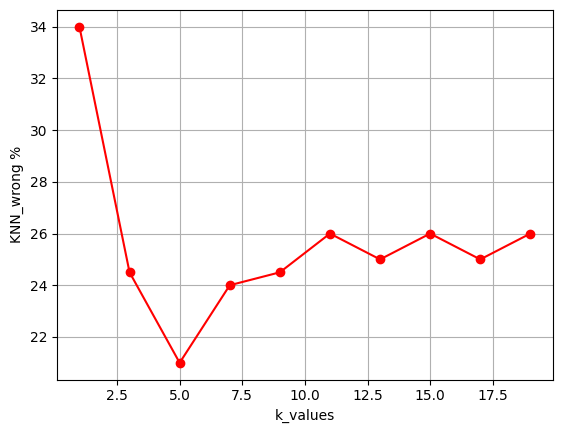

In [ ]:
plt.plot(k_values,wrong_sklearn,marker='o',color='red')
plt.grid(True)
plt.xlabel("k_values")
plt.ylabel("KNN_wrong %")
plt.show()